# Where ML wins, and where prediction remains difficult

All results below come from saved held-out artifacts. Site descriptors use only the
training period. Sites are stratified by Köppen class, so they are not an area-weighted
global sample.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from skillmap.config import PROCESSED, FIGURES, SPLITS, WEATHER_COLUMNS
findings = json.loads((PROCESSED / 'findings.json').read_text())
sites = pd.read_csv(PROCESSED / 'sites.csv', keep_default_na=False)
predictions = pd.read_parquet(PROCESSED / 'predictions.parquet')
selected = sites[sites.site_id.isin(findings['site_ids'])]
display(Markdown(f"This run evaluates **{findings['n_sites']} complete sites**. "
                 f"The full sampling frame contains **{len(sites)} sites**."))

This run evaluates **200 complete sites**. The full sampling frame contains **200 sites**.

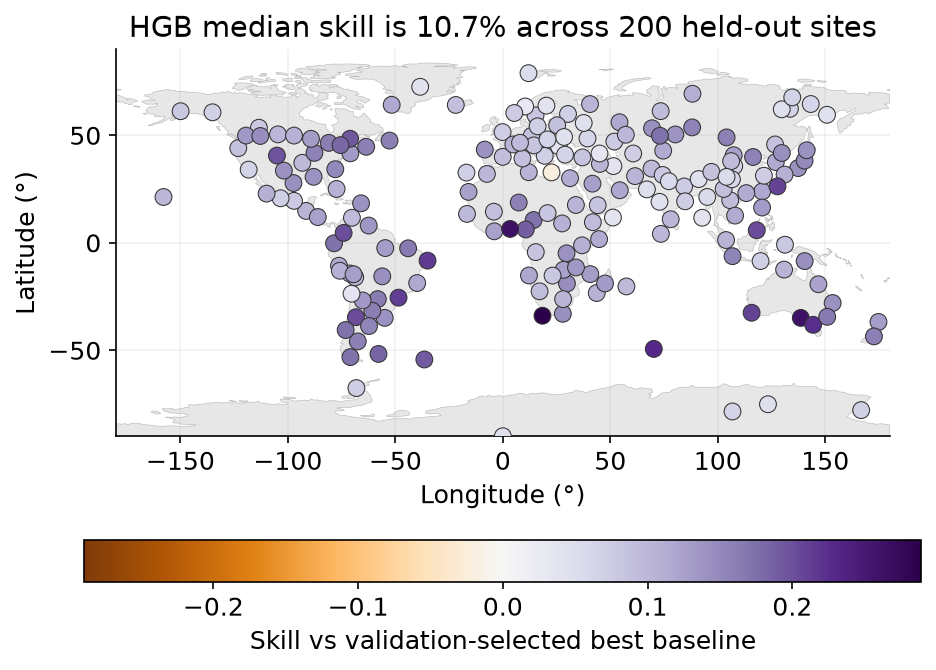

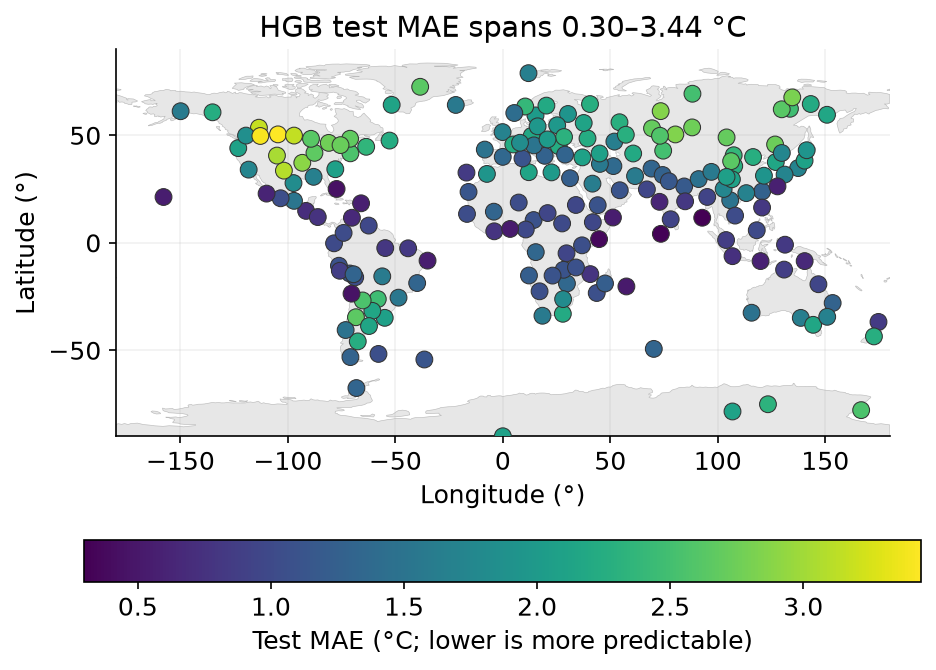

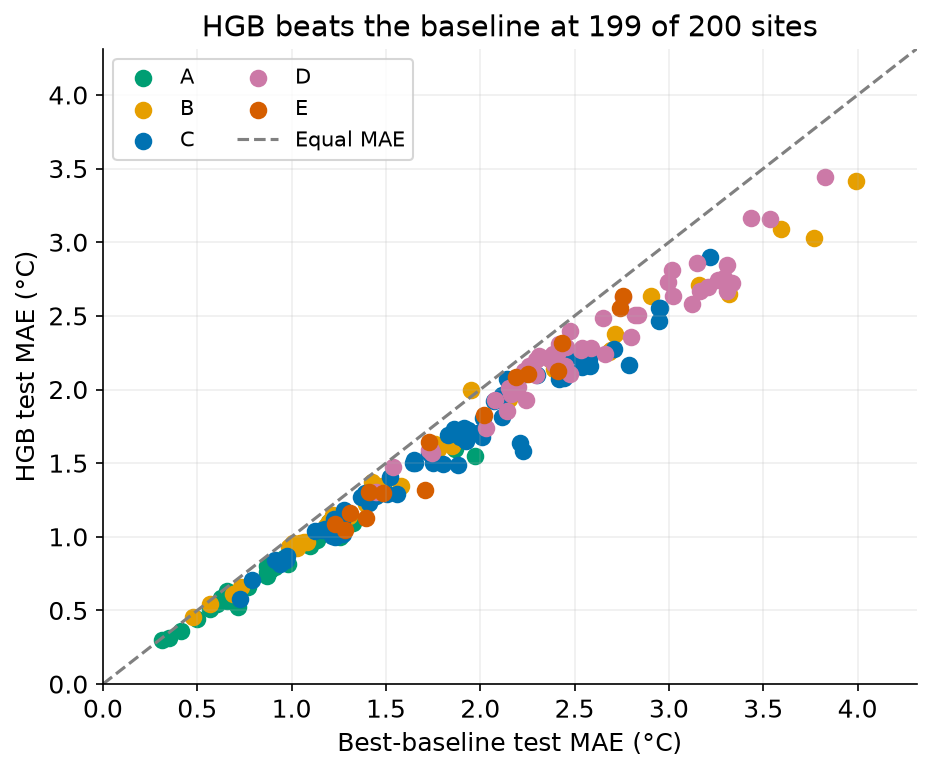

,model,reference,median_skill,q25_skill,q75_skill,n_sites,n_significant,fraction_significant
0,hgb,best_baseline,0.106948,0.077791,0.141767,200,191,0.955
1,hgb,climatology,0.337634,0.278555,0.407895,200,200,1.000
2,hgb,persistence,0.108329,0.076709,0.142701,200,190,0.950
3,hgb_pooled,best_baseline,0.100392,0.080401,0.129605,200,190,0.950
4,hgb_pooled,climatology,0.331447,0.269533,0.410483,200,199,0.995
5,hgb_pooled,persistence,0.101980,0.082327,0.132367,200,191,0.955
6,linear,best_baseline,0.102707,0.070466,0.126386,200,191,0.955
7,linear,climatology,0.329437,0.269409,0.403439,200,200,1.000
8,linear,persistence,0.105173,0.070640,0.127199,200,191,0.955


In [2]:
def figure(name):
    display(Image(filename=str(FIGURES / name), width=900))
figure('skill_map.png')
figure('mae_map.png')
figure('baseline_vs_model.png')
display(pd.DataFrame(findings['skill_summary']))

## Climate groups and training-period drivers

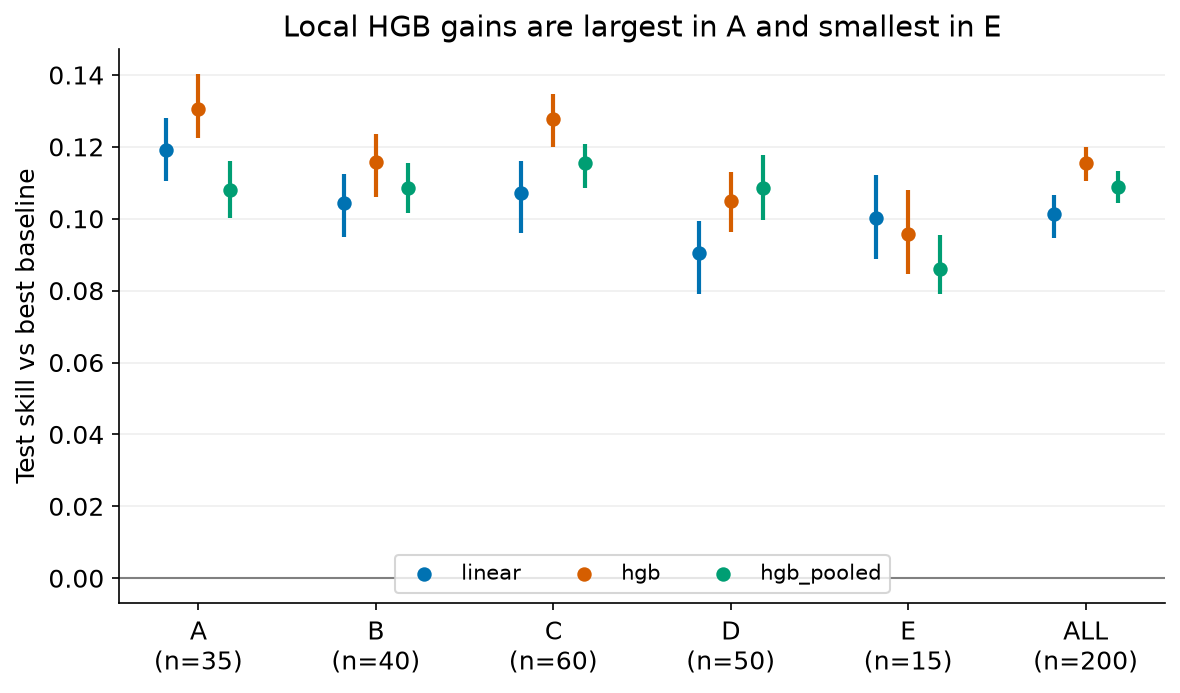

,best,worst
hgb,"{'koppen_group': 'A', 'split': 'test', 'model'...","{'koppen_group': 'E', 'split': 'test', 'model'..."
hgb_pooled,"{'koppen_group': 'C', 'split': 'test', 'model'...","{'koppen_group': 'E', 'split': 'test', 'model'..."
linear,"{'koppen_group': 'A', 'split': 'test', 'model'...","{'koppen_group': 'D', 'split': 'test', 'model'..."


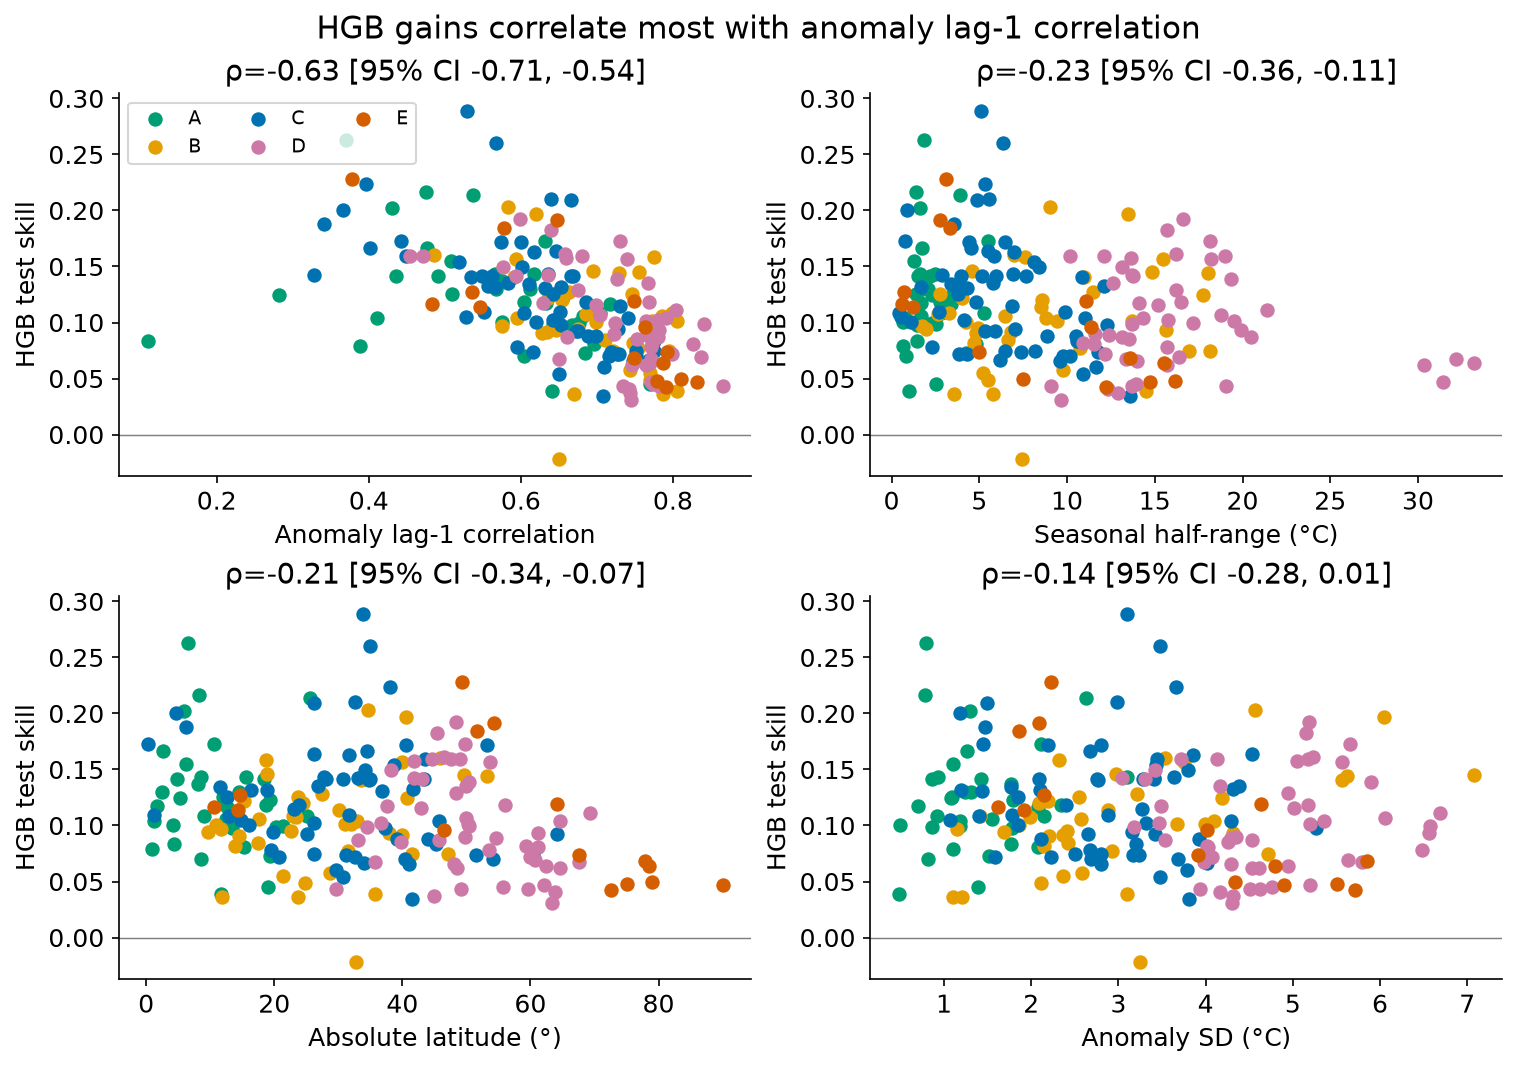

,model,reference,outcome,driver,rho,ci_low,ci_high,n_sites,n_valid_reps,absolute_rho
0,hgb,best_baseline,skill,anomaly_acf1,-0.634499,-0.708543,-0.543625,200,1000,0.634499
1,linear,best_baseline,skill,anomaly_acf1,-0.627325,-0.704782,-0.527260,200,1000,0.627325
2,hgb_pooled,best_baseline,skill,anomaly_acf1,-0.529827,-0.635872,-0.404654,200,1000,0.529827
3,linear,best_baseline,skill,seasonal_amplitude,-0.298623,-0.413939,-0.164222,200,1000,0.298623
4,linear,best_baseline,skill,anomaly_sd,-0.247464,-0.375922,-0.101807,200,1000,0.247464
5,hgb,best_baseline,skill,seasonal_amplitude,-0.233764,-0.355418,-0.106085,200,1000,0.233764
6,linear,best_baseline,skill,abs_lat,-0.230262,-0.346611,-0.088338,200,1000,0.230262
7,hgb,best_baseline,skill,abs_lat,-0.214543,-0.344077,-0.069918,200,1000,0.214543
8,hgb_pooled,best_baseline,skill,daily_change,0.183608,0.032889,0.334090,200,1000,0.183608
9,hgb,best_baseline,skill,anomaly_sd,-0.141269,-0.278303,0.006529,200,1000,0.141269


In [3]:
figure('skill_by_group.png')
display(pd.DataFrame(findings['group_extremes']).T)
figure('skill_vs_driver.png')
display(pd.DataFrame(findings['top_driver_correlations']))

Correlations are descriptive associations across sampled sites. Bootstrap intervals do
not adjust for testing several drivers. Weather variability, latitude and climate class
are related, so these associations should not be read as independent causal effects.

## Calendar months, local seasons and losing sites

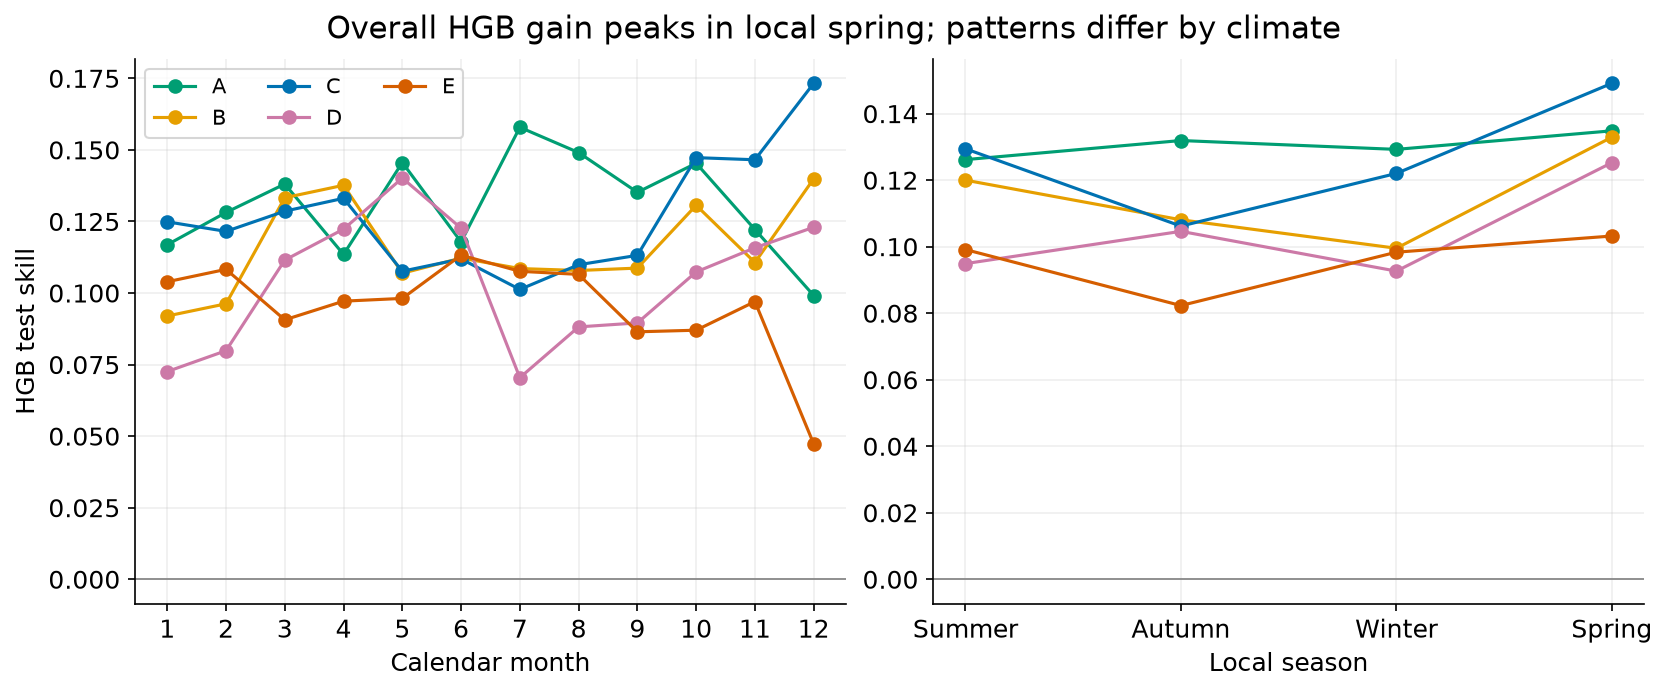

,period_type,period,koppen_group,model,reference,mae_model,mae_ref,skill,n_sites,n_pairs
1091,local_season,autumn,A,hgb,best_baseline,0.797653,0.918866,0.131916,35,6404
1106,local_season,autumn,B,hgb,best_baseline,1.435361,1.609300,0.108084,40,7294
1121,local_season,autumn,C,hgb,best_baseline,1.490696,1.667797,0.106188,60,10968
1136,local_season,autumn,D,hgb,best_baseline,2.115384,2.362541,0.104615,50,9100
1151,local_season,autumn,E,hgb,best_baseline,1.769232,1.927885,0.082294,15,2752
1166,local_season,autumn,ALL,hgb,best_baseline,1.535409,1.718227,0.106400,200,36518
1181,local_season,spring,A,hgb,best_baseline,0.876624,1.013248,0.134838,35,6406
1196,local_season,spring,B,hgb,best_baseline,1.774596,2.046640,0.132922,40,7346
1211,local_season,spring,C,hgb,best_baseline,1.761886,2.070667,0.149121,60,10992
1226,local_season,spring,D,hgb,best_baseline,2.501169,2.859343,0.125264,50,9200


,site_id,name,model,skill,ci_low,ci_high,significant_loss,plausible_reasons
0,gn-87205,Darnah,hgb,-0.021537,-0.093585,0.040135,False,[above-median day-to-day variability may limit...


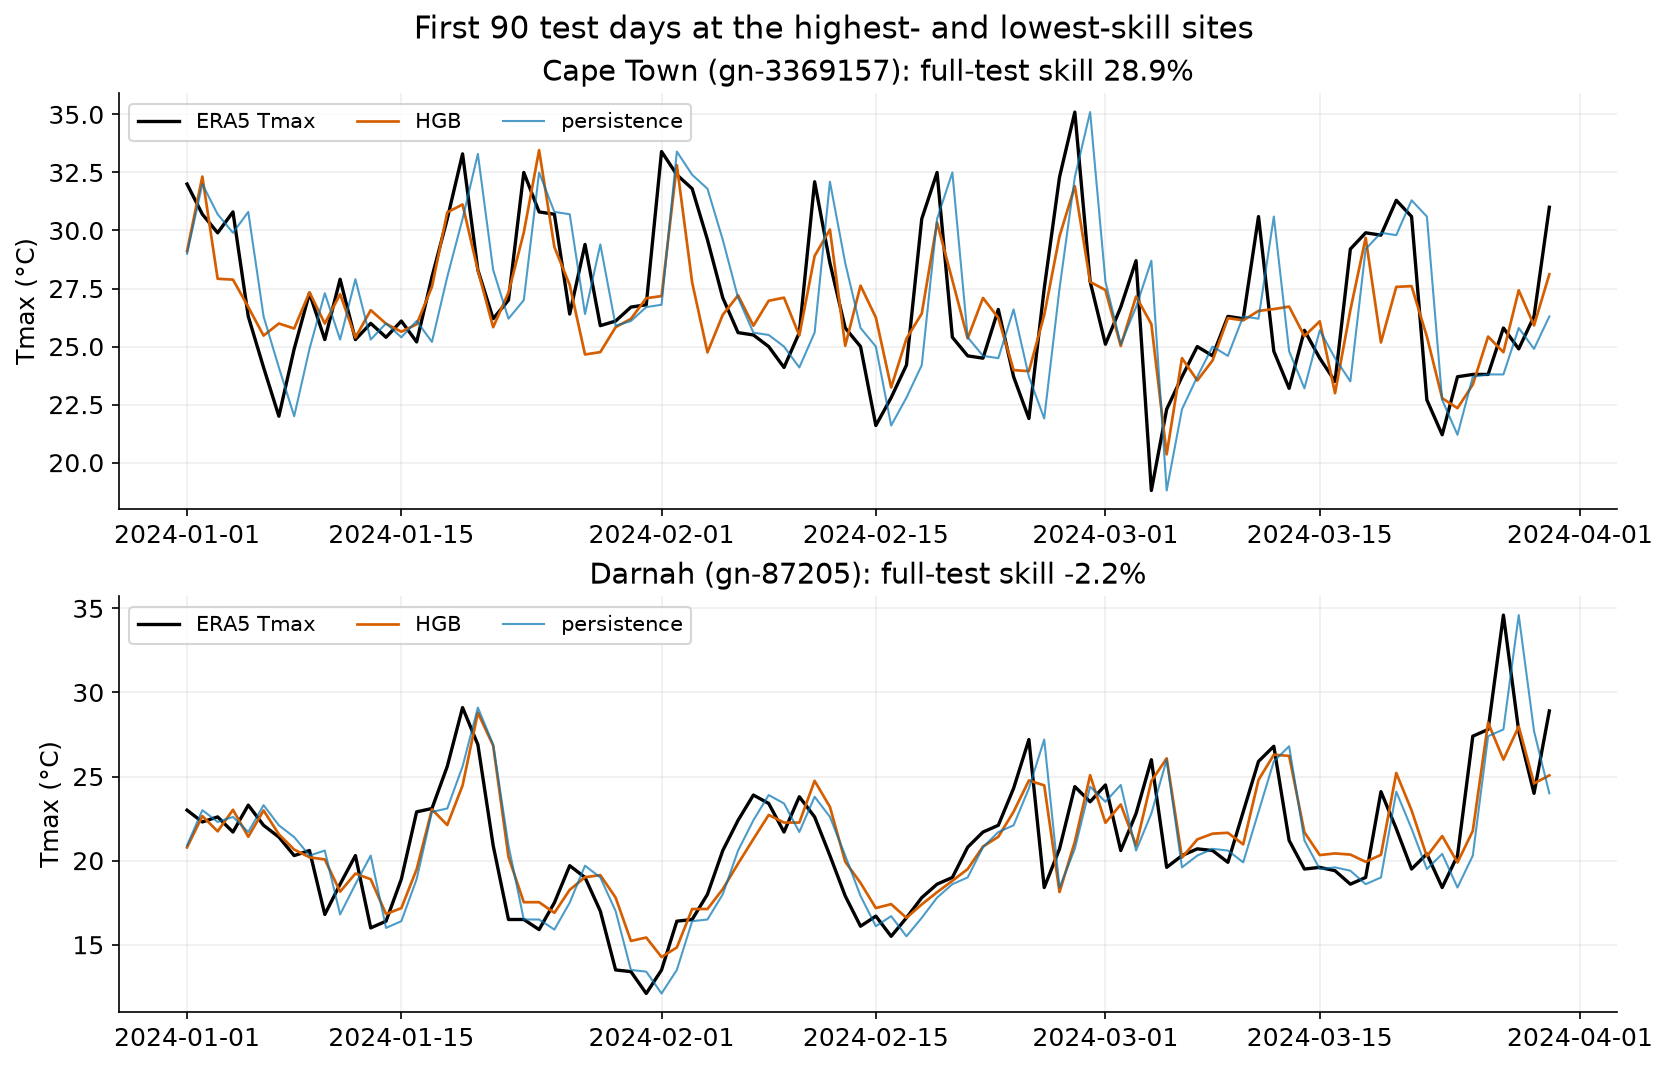

In [4]:
figure('seasonal.png')
seasonal = pd.read_csv(PROCESSED / 'seasonal_group.csv')
display(seasonal.query("period_type == 'local_season' and model == 'hgb' "
                       "and reference == 'best_baseline' and n_sites > 0"))
losing = pd.DataFrame(findings['losing_sites'])
display(losing if len(losing) else Markdown('No negative point-skill sites in this run.'))
figure('example_city.png')

Local seasons reverse north/south meteorological seasons; the equator uses the northern
convention. Tropical wet/dry seasons need a different treatment. Losing-site explanations
are driver-based hypotheses, not established causes. Example cities are selected after
evaluation as illustrations of extremes; their snippets are not a new evaluation set.

## Local versus pooled, and weather-feature ablation

mean_mae_local                     1.641165
mean_mae_pooled                    1.653328
mean_delta_pooled_minus_local      0.012163
median_delta_pooled_minus_local    0.009280
fraction_pooled_better             0.365000
dtype: float64

,model,mean,median
0,hgb,-0.079547,-0.061027
1,hgb_pooled,-0.052047,-0.030990
2,linear,-0.059578,-0.040938


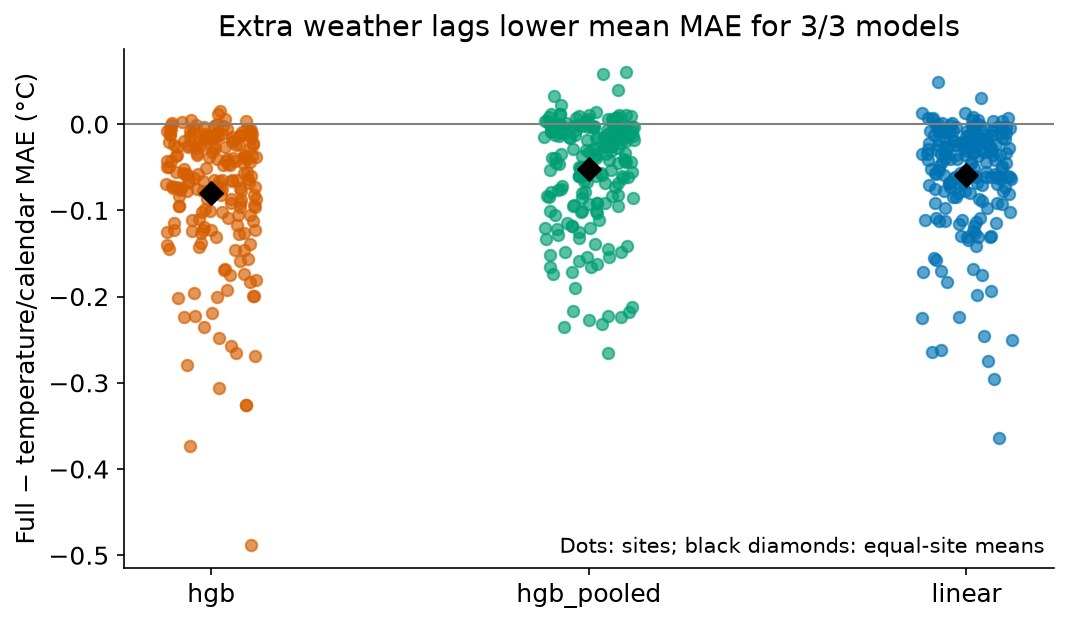

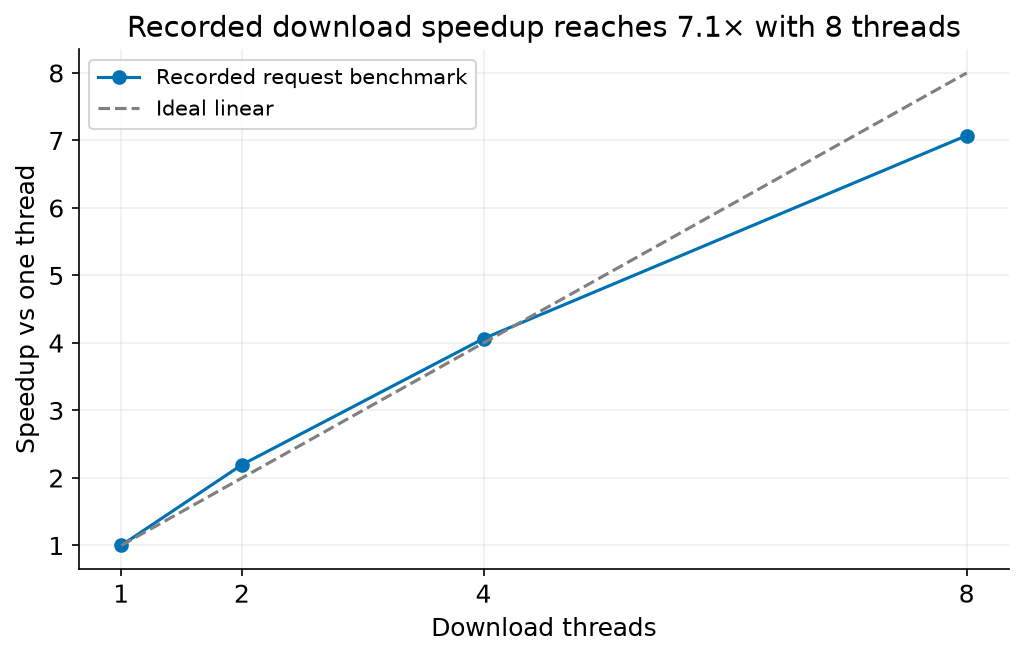

In [5]:
display(pd.Series(findings['pooled_vs_local']))
display(pd.DataFrame(findings['ablation_deltas']))
figure('ablation.png')
figure('concurrency_speedup.png')

## Computed conclusion

In [6]:
lines = [f"This held-out run covers {findings['n_sites']} complete sites."]
for row in findings['skill_summary']:
    if row['reference'] == 'best_baseline':
        lines.append(
            f"{row['model']}: median skill {row['median_skill']:.1%} "
            f"(IQR {row['q25_skill']:.1%}–{row['q75_skill']:.1%}); "
            f"{row['n_significant']}/{row['n_sites']} sites have a 95% interval above zero."
        )
pooled = findings['pooled_vs_local']
if pooled:
    lines.append(f"Pooled minus local HGB mean MAE is "
                 f"{pooled['mean_delta_pooled_minus_local']:+.3f} °C; "
                 f"pooling improves {pooled['fraction_pooled_better']:.1%} of sites.")
lines.extend(findings['caveats'])
display(Markdown(chr(10).join(lines)))

This held-out run covers 200 complete sites.
hgb: median skill 10.7% (IQR 7.8%–14.2%); 191/200 sites have a 95% interval above zero.
hgb_pooled: median skill 10.0% (IQR 8.0%–13.0%); 190/200 sites have a 95% interval above zero.
linear: median skill 10.3% (IQR 7.0%–12.6%); 191/200 sites have a 95% interval above zero.
Pooled minus local HGB mean MAE is +0.012 °C; pooling improves 36.5% of sites.
Sites are stratified by Koppen class, not area-weighted; not global means.
Intervals are conditional on fitted models; no model-selection uncertainty.
Exploratory driver correlations have no multiple-comparison adjustment.
Loss explanations are hypotheses, not causal conclusions.
Local seasons are meteorological; tropical wet/dry seasons are not represented.